# LoopMR demo: CC359 test slice

LoopMR applies **one** SDUM-Restormer block 12 times, with soft data consistency in k-space, 5 adjacent slices and 4 carried latent
images (10.27M parameters including PromptMR+'s sensitivity estimator). This notebook loads the released CC359 weights, reconstructs a
slice of PromptMR+'s test split at R = 5 and R = 10 with that volume's fixed test mask, and shows the image after each loop.
Needs the prepared CC359 data (`data_prep/README.md`); runs on GPU or CPU.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from loopmri.data import batch_to_device, build_dataset
from loopmri.evaluate import load_model
from loopmri.metrics import challenge_volume
from loopmri.mri import centre_chunk, kspace_to_rss

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model, cfg, step = load_model(str(ROOT / "weights/cc359_rs5_fd_146k.pt"), device)
n = lambda m: sum(p.numel() for p in m.parameters())
print(f"step {step}, device {device}: {n(model) / 1e6:.2f}M parameters (sensitivity estimator {n(model.sens_net) / 1e6:.2f}M, "
      f"block {n(model.denoiser) / 1e6:.2f}M); {model.A} adjacent slices, {model.K} latents, {model.eval_loops} loops")

step 146640, device cuda: 10.27M parameters (sensitivity estimator 1.87M, block 8.40M); 5 adjacent slices, 4 latents, 12 loops


## Reconstruction at R = 5 and R = 10
The middle scored slice of the first test volume. Scores are the Calgary-Campinas challenge metric of this one slice (the reported
numbers average it over every slice of every test volume: `python -m loopmri.evaluate`).

e14110s3_P59904.7.h5 slice 128, R = 5: zero-filled SSIM 0.7799 / PSNR 27.09 dB | LoopMR (12 loops) SSIM 0.9575 / PSNR 38.87 dB


e14110s3_P59904.7.h5 slice 128, R = 10: zero-filled SSIM 0.7426 / PSNR 26.17 dB | LoopMR (12 loops) SSIM 0.9448 / PSNR 37.05 dB


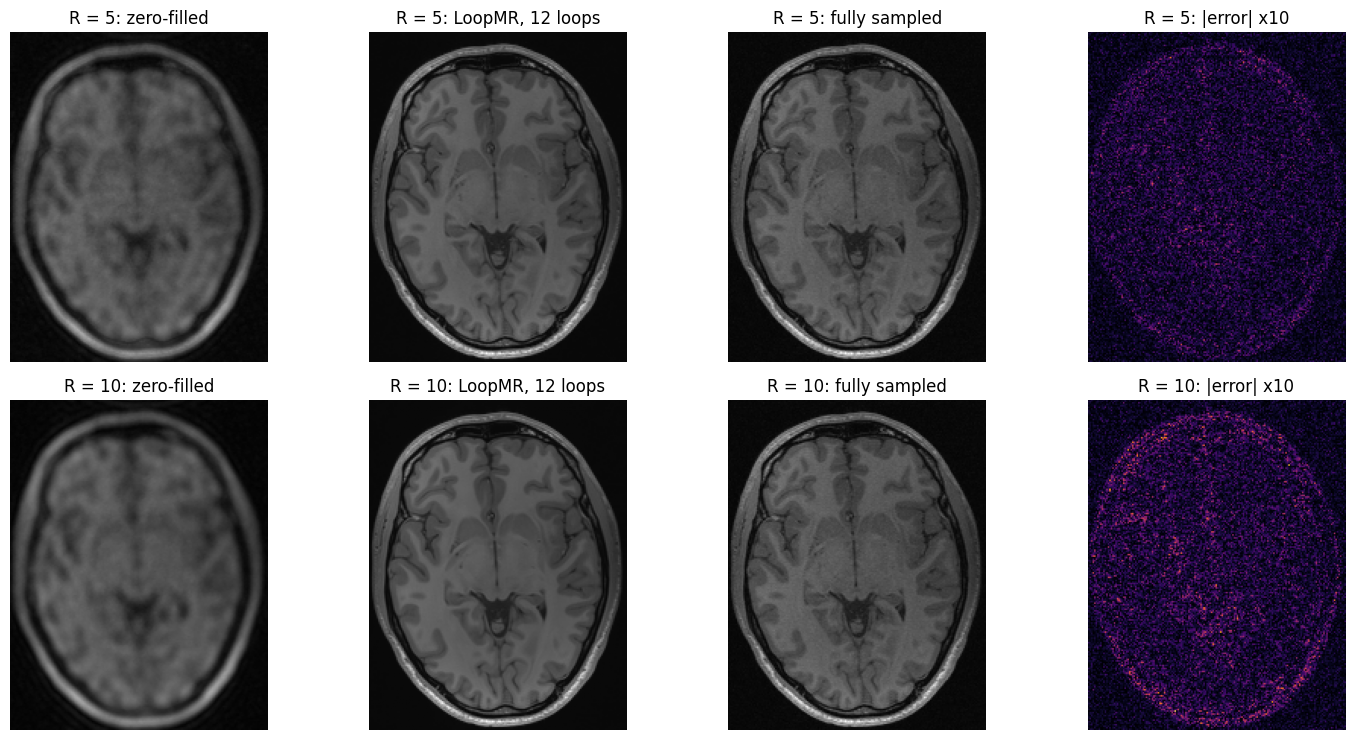

In [2]:
LOOPS = list(range(1, 13))
cases = {}
for R in (5, 10):
    ds = build_dataset(cfg["data"], "test", train=False, split_json="configs/splits/cc359_promptmr.json", accelerations=[R])
    fname = sorted({p.name for p, _ in ds.samples})[0]
    idx = [i for i, (p, _) in enumerate(ds.samples) if p.name == fname]
    s = ds[idx[len(idx) // 2]]
    b = batch_to_device({k: (v[None] if torch.is_tensor(v) else [v] if isinstance(v, str) else torch.tensor([v])) for k, v in s.items()}, device)
    recs = model.reconstruct(b["masked_kspace"], b["mask"], b["num_low_frequencies"], loops=LOOPS)
    target = b["target"][0].cpu().numpy()
    zf = kspace_to_rss(centre_chunk(b["masked_kspace"], model.A))[0].cpu().numpy()
    cases[R] = {"target": target, "zf": zf, "recs": {t: r[0].float().cpu().numpy() for t, r in recs.items()}}
    score = lambda img: challenge_volume(target[None], img[None])
    print(f"{fname} slice {s['slice_num']}, R = {R}: zero-filled SSIM {score(zf)['ssim']:.4f} / PSNR {score(zf)['psnr']:.2f} dB | "
          f"LoopMR (12 loops) SSIM {score(cases[R]['recs'][12])['ssim']:.4f} / PSNR {score(cases[R]['recs'][12])['psnr']:.2f} dB")

fig, ax = plt.subplots(2, 4, figsize=(15, 7.5))
for row, R in enumerate((5, 10)):
    c = cases[R]
    vmax = c["target"].max()
    for col, (img, title) in enumerate(((c["zf"], "zero-filled"), (c["recs"][12], "LoopMR, 12 loops"), (c["target"], "fully sampled"))):
        ax[row, col].imshow(img, cmap="gray", vmin=0, vmax=vmax); ax[row, col].set_title(f"R = {R}: {title}")
    ax[row, 3].imshow(np.abs(c["recs"][12] - c["target"]), cmap="inferno", vmin=0, vmax=0.1 * vmax)
    ax[row, 3].set_title(f"R = {R}: |error| x10")
for a in ax.flat:
    a.axis("off")
plt.tight_layout(); plt.show()

## The image after each loop
The same block is applied at every loop; the model is trained and evaluated at 12 loops.

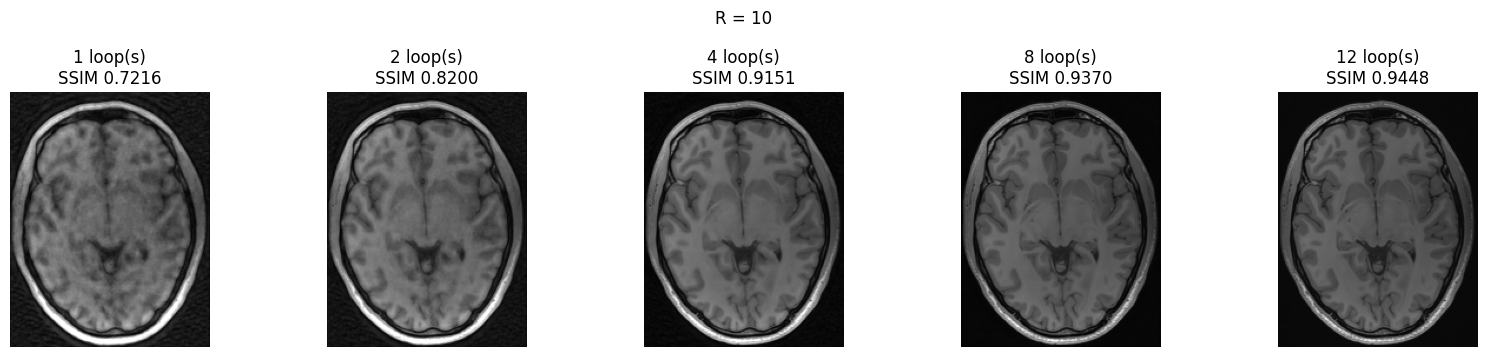

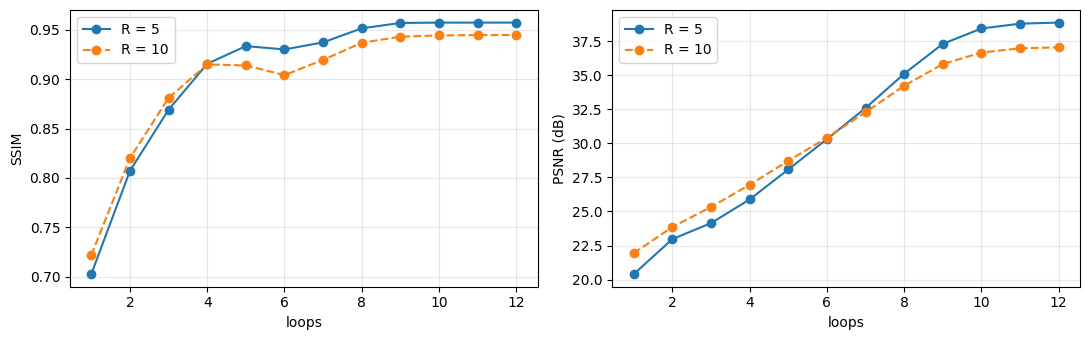

In [3]:
show = [1, 2, 4, 8, 12]
fig, ax = plt.subplots(1, len(show), figsize=(3.2 * len(show), 3.6))
c = cases[10]
for a, t in zip(ax, show):
    sc = challenge_volume(c["target"][None], c["recs"][t][None])
    a.imshow(c["recs"][t], cmap="gray", vmin=0, vmax=c["target"].max()); a.set_title(f"{t} loop(s)\nSSIM {sc['ssim']:.4f}"); a.axis("off")
plt.suptitle("R = 10"); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for R, ls in ((5, "-"), (10, "--")):
    sc = [challenge_volume(cases[R]["target"][None], cases[R]["recs"][t][None]) for t in LOOPS]
    ax[0].plot(LOOPS, [x["ssim"] for x in sc], ls, marker="o", label=f"R = {R}")
    ax[1].plot(LOOPS, [x["psnr"] for x in sc], ls, marker="o", label=f"R = {R}")
for a, yl in zip(ax, ("SSIM", "PSNR (dB)")):
    a.set_xlabel("loops"); a.set_ylabel(yl); a.grid(alpha=0.3); a.legend()
plt.tight_layout(); plt.show()